In [77]:
import os
import tarfile
import urllib
DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
HOUSING_PATH = os.path.join("datasets", "housing")
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"
def fetch_housing_data(housing_url=HOUSING_URL, housing_path=HOUSING_PATH):
    os.makedirs(housing_path, exist_ok=True)
    tgz_path = os.path.join(housing_path, "housing.tgz")
    urllib.request.urlretrieve(housing_url, tgz_path)
    housing_tgz = tarfile.open(tgz_path)
    housing_tgz.extractall(path=housing_path)
    housing_tgz.close()


In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [79]:
fetch_housing_data()

C:\Users\conne\AppData\Local\Temp\ipykernel_20420\924802912.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  housing_tgz.extractall(path=housing_path)


In [80]:
data = pd.read_csv(r'datasets/housing/housing.csv')
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [81]:
data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [82]:
data['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

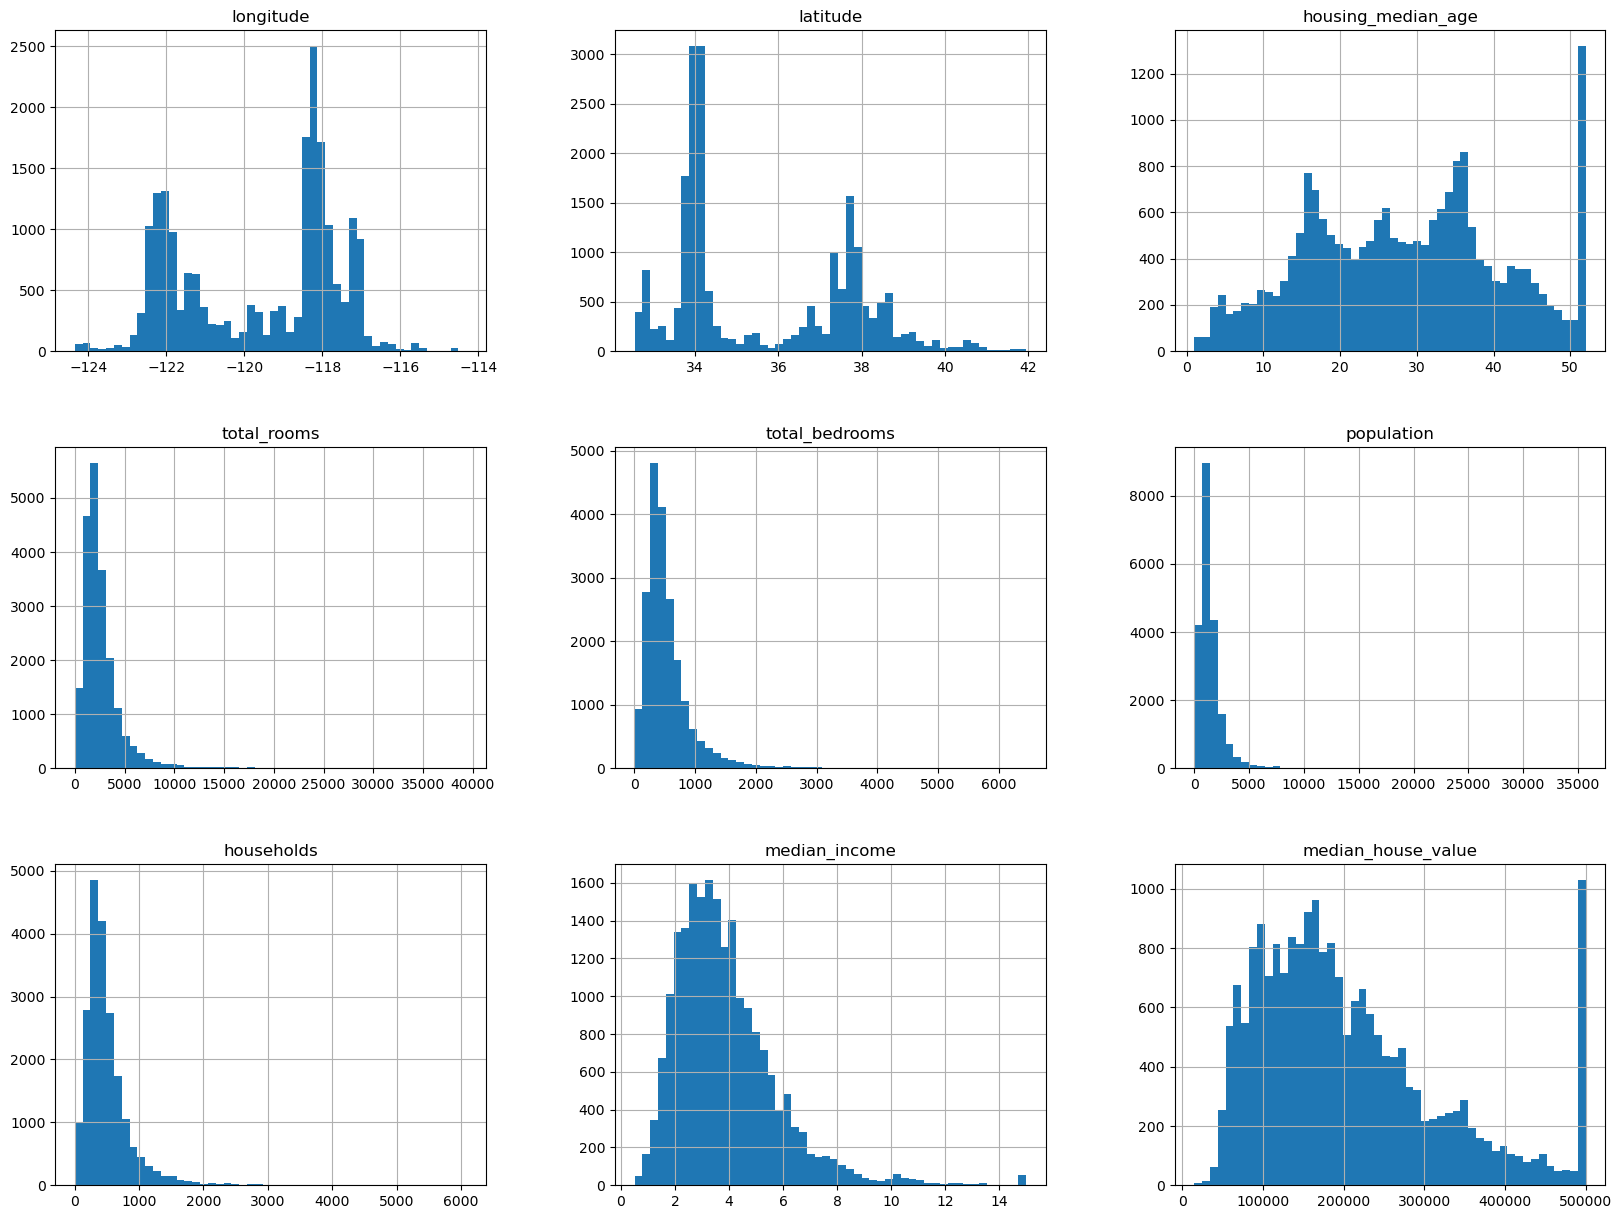

In [83]:
data.hist(bins=50,figsize = (20,15))


In [84]:
from zlib import crc32
import numpy as np
def hash_index(index,test_ratio):
    return crc32(np.int64(index))&0xffffffff < test_ratio* (2**32)

"""
0xffffffff - to make it an unsigned int
check if hashed number is less than 20 percent of the total range of int
if so it belongs to test set else training set
"""

def split_by_id(data,test_ratio,id_index):
    ids = data[id_index]
    in_test_set = ids.apply(lambda _id : hash_index(_id,test_ratio))
    return data.loc[~in_test_set],data.loc[in_test_set]
"""
Since we are using boolean conditions , we are using loc instead of iloc
"""

'\nSince we are using boolean conditions , we are using loc instead of iloc\n'

In [85]:
data = data.reset_index()

In [86]:
train,test = split_by_id(data,0.2,'index')

In [87]:
len(train)
len(test)

4128

In [88]:
np.unique(data['median_income'])

array([ 0.4999,  0.536 ,  0.5495, ..., 14.9009, 15.    , 15.0001],
      shape=(12928,))

In [89]:
data['income_cat']=pd.cut(data['median_income'], 
        bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
        labels=[1, 2, 3, 4,5])

<Axes: >

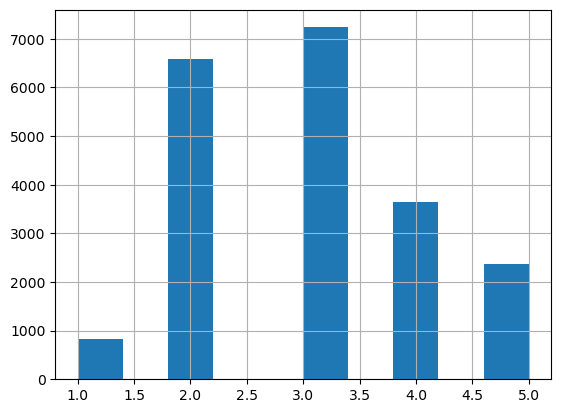

In [90]:
data['income_cat'].hist()

In [91]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
for train_index,test_index in split.split(data,data['income_cat']):
    strat_train = data.loc[train_index]
    strat_test = data.loc[test_index]
    print(train_index)
    print(test_index)

[12655 15502  2908 ... 19263 19140 19773]
[ 5241 17352  3505 ... 17223 10786  3965]


In [92]:
data.head()

,index,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,income_cat
0,0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,5
1,1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,5
2,2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,5
3,3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,4
4,4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,3


In [93]:
data.drop(columns=['median_income'],inplace=True)

<Axes: xlabel='longitude', ylabel='latitude'>

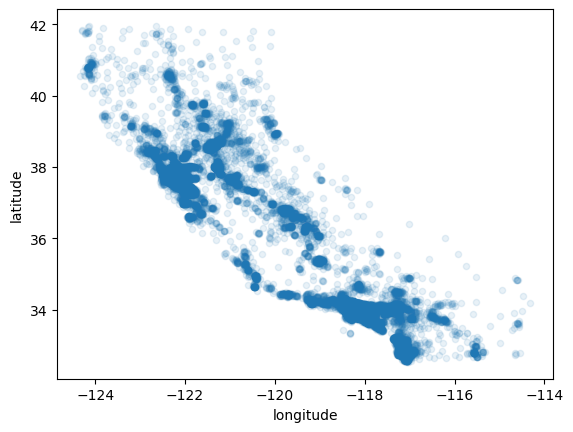

In [94]:
data.plot(kind = 'scatter',x='longitude',y='latitude',alpha=0.1)

array([[<Axes: xlabel='median_house_value', ylabel='median_house_value'>,
        <Axes: xlabel='total_rooms', ylabel='median_house_value'>,
        <Axes: xlabel='housing_median_age', ylabel='median_house_value'>],
       [<Axes: xlabel='median_house_value', ylabel='total_rooms'>,
        <Axes: xlabel='total_rooms', ylabel='total_rooms'>,
        <Axes: xlabel='housing_median_age', ylabel='total_rooms'>],
       [<Axes: xlabel='median_house_value', ylabel='housing_median_age'>,
        <Axes: xlabel='total_rooms', ylabel='housing_median_age'>,
        <Axes: xlabel='housing_median_age', ylabel='housing_median_age'>]],
      dtype=object)

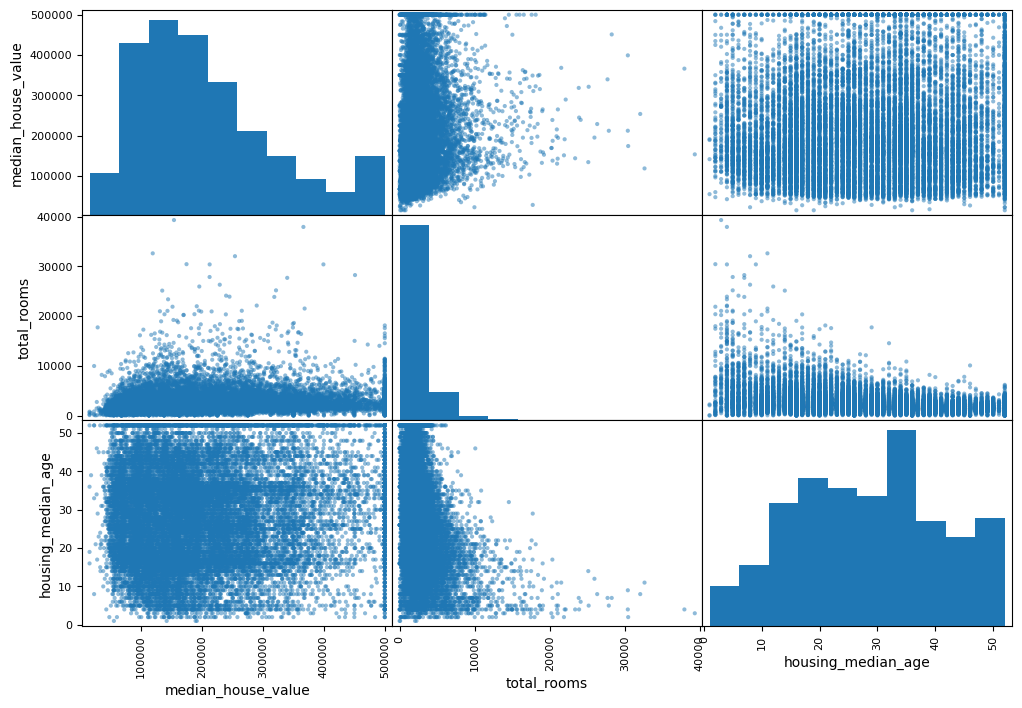

In [95]:
from pandas.plotting import scatter_matrix
attributes = ["median_house_value", "total_rooms",
    "housing_median_age"]
scatter_matrix(data[attributes], figsize=(12, 8))

In [96]:
df=data.drop(columns=['ocean_proximity'])

In [97]:
corr_mat = df.corr()
corr_mat['median_house_value'].sort_values(ascending=True)

latitude             -0.144160
longitude            -0.045967
population           -0.024650
total_bedrooms        0.049686
households            0.065843
index                 0.072086
housing_median_age    0.105623
total_rooms           0.134153
income_cat            0.643892
median_house_value    1.000000
Name: median_house_value, dtype: float64

In [98]:
df.columns

Index(['index', 'longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_house_value',
       'income_cat'],
      dtype='object')

In [99]:
df.head()

,index,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_house_value,income_cat
0,0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,452600.0,5
1,1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,358500.0,5
2,2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,352100.0,5
3,3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,341300.0,4
4,4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,342200.0,3


In [100]:
df['rooms_per_household'] = df['total_rooms']/df['households']
df['population_per_household'] = df['population']/df['households']
df["bedrooms_per_room"] = df["total_bedrooms"]/df["total_rooms"]

In [101]:
corr_mat = df.corr()
corr_mat['median_house_value'].sort_values(ascending=True)

bedrooms_per_room          -0.255880
latitude                   -0.144160
longitude                  -0.045967
population                 -0.024650
population_per_household   -0.023737
total_bedrooms              0.049686
households                  0.065843
index                       0.072086
housing_median_age          0.105623
total_rooms                 0.134153
rooms_per_household         0.151948
income_cat                  0.643892
median_house_value          1.000000
Name: median_house_value, dtype: float64

<Axes: xlabel='median_house_value', ylabel='rooms_per_household'>

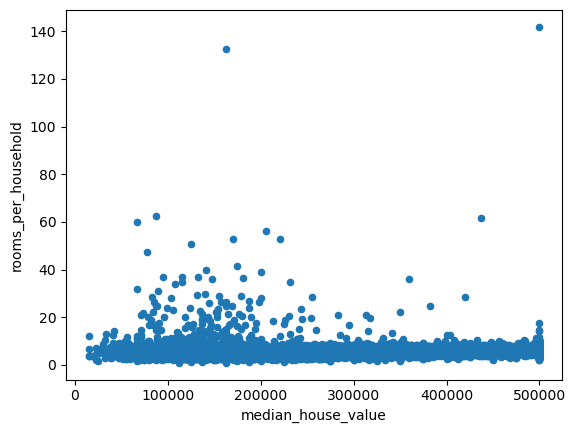

In [102]:
df.plot(kind='scatter',x='median_house_value',y='rooms_per_household')

In [103]:
final = strat_train.drop("median_house_value",axis=1)
label = strat_train["median_house_value"].copy()
print(final.shape,label.shape)

(16512, 11) (16512,)


In [104]:
final.isna().sum()

index                   0
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        158
population              0
households              0
median_income           0
ocean_proximity         0
income_cat              0
dtype: int64

In [105]:
from sklearn.impute import SimpleImputer
sin = SimpleImputer(strategy='mean')
final_num = final.drop(columns=['ocean_proximity'])
final_num=sin.fit_transform(final_num)
final_num=pd.DataFrame(final_num)
final_num.head()

,0,1,2,3,4,5,6,7,8,9
0,12655.0,-121.46,38.52,29.0,3873.0,797.0,2237.0,706.0,2.1736,2.0
1,15502.0,-117.23,33.09,7.0,5320.0,855.0,2015.0,768.0,6.3373,5.0
2,2908.0,-119.04,35.37,44.0,1618.0,310.0,667.0,300.0,2.8750,2.0
3,14053.0,-117.13,32.75,24.0,1877.0,519.0,898.0,483.0,2.2264,2.0
4,20496.0,-118.70,34.28,27.0,3536.0,646.0,1837.0,580.0,4.4964,3.0


In [106]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
pipe = Pipeline(
    [
        ("imputer",SimpleImputer(strategy='mean')),
        ('std scaler',StandardScaler())
    ]
)


In [107]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(final_num,label)


LinearRegression()

In [108]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
forest = RandomForestRegressor()
params=[{
    'n_estimators':[3,10,30],
    'max_features':[2,4,6,8],

}]
gcv = GridSearchCV(
    forest,
    params,
    cv=5,
    return_train_score=True

)
gcv.fit(final_num,label)


GridSearchCV(cv=5, estimator=RandomForestRegressor(),
             param_grid=[{'max_features': [2, 4, 6, 8],
                          'n_estimators': [3, 10, 30]}],
             return_train_score=True)

In [109]:
gcv.best_estimator_

RandomForestRegressor(max_features=8, n_estimators=30)

In [110]:
gcv.best_estimator_.feature_importances_

array([0.09327492, 0.12596568, 0.11302504, 0.06025347, 0.02412462,
       0.02359765, 0.03167868, 0.0203578 , 0.42422426, 0.08349787])

In [111]:
final_model = gcv.best_estimator_
x_test=strat_test.drop(columns=['median_house_value'],axis=1)
y_test=strat_test['median_house_value'].copy()
y_test.drop(columns=['ocean_proximity'],axis=1,inplace=True)
y_pred = final_model.predict(x_test)


d:\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


ValueError: could not convert string to float: '<1H OCEAN'